## -------------------------------------------------------------------------------------------------------------------

# PROYECTO DEL CEIEC
# Jupyter para el entrenamiento de un modelo LSTM
# Autor: Carlos Arranz Luque

## -------------------------------------------------------------------------------------------------------------------

## Librerías

In [1]:
from numpy import mean
from numpy import std
from numpy import dstack
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Flatten
from keras.layers import Dropout
from keras.layers import LSTM
from keras.utils import to_categorical
import numpy as np
import pandas as pd
import pickle
from sklearn.model_selection import train_test_split
import numpy as np 
from tensorflow import keras
from matplotlib import pyplot as plt
from IPython.display import clear_output
import matplotlib.pyplot as plt

## Metricas
from sklearn.metrics import cohen_kappa_score
from sklearn.metrics import matthews_corrcoef
from sklearn.metrics import log_loss
from sklearn.metrics import roc_auc_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

In [2]:
nombreFicheros =  '3533364bd4bf7a6e0d7306a2eff4d975'
cargarPesos = False

In [3]:
if(cargarPesos == True):
    file_pesos_modelo = open('Objetos preprocesados/Pesos_LSTM/'+nombreFicheros+'_pesosLSTM.obj', 'rb')
    weights = pickle.load(file_pesos_modelo)
    file_pesos_modelo.close()

## Clase para mostrar un gráfico del error y el acierto del modelo según se va entrenando

In [4]:
class PlotLearning(keras.callbacks.Callback):
    """
    Callback to plot the learning curves of the model during training.
    """
    def on_train_begin(self, logs={}):
        self.metrics = {}
        for metric in logs:
            self.metrics[metric] = []
            

    def on_epoch_end(self, epoch, logs={}):
        # Storing metrics
        for metric in logs:
            if metric in self.metrics:
                self.metrics[metric].append(logs.get(metric))
            else:
                self.metrics[metric] = [logs.get(metric)]
        
        # Plotting
        metrics = [x for x in logs if 'val' not in x]
        
        f, axs = plt.subplots(1, len(metrics), figsize=(15,5))
        clear_output(wait=True)

        for i, metric in enumerate(metrics):
            axs[i].plot(range(1, epoch + 2), 
                        self.metrics[metric], 
                        label=metric)
            if logs['val_' + metric]:
                axs[i].plot(range(1, epoch + 2), 
                            self.metrics['val_' + metric], 
                            label='val_' + metric)
                
            axs[i].legend()
            axs[i].grid()

        plt.tight_layout()
        plt.show()

## Cargar el array tridimensional con los semiflujos y el array con las etiquetas de estos semiflujos

In [5]:
archivo = open('Objetos preprocesados/Semiflujos/'+nombreFicheros+'_array_etiquetas.obj', 'rb') 
array_etiquetas = pickle.load(archivo)


archivo = open('Objetos preprocesados/Semiflujos/'+nombreFicheros+'_array_tridimensional.obj', 'rb') 
array_semiflujos = pickle.load(archivo)

In [6]:
print('Dimensionalidad del array de semiflujos cargado: '+str(array_semiflujos.shape))
print('Dimensionalidad del array de etiquetas cargado: '+str(array_etiquetas.shape))


Dimensionalidad del array de semiflujos cargado: (689654, 20, 101)
Dimensionalidad del array de etiquetas cargado: (689654, 5)


## Toca dividir entre training y test, reorganizamos los datos de forma aleatoria también

In [8]:
#0.1
X_train_bruto, X_test, y_train_bruto, y_test = train_test_split(array_semiflujos, array_etiquetas, test_size=0.1, shuffle = True, random_state=42)

X_train, X_validation, y_train, y_validation = train_test_split(X_train_bruto, y_train_bruto, test_size=0.111111, shuffle = True, random_state=42)


print('Dimensionalidad del array de semiflujos train: '+str(X_train.shape))
print('Dimensionalidad del array de etiquetas train: '+str(y_train.shape))
print('Dimensionalidad del array de semiflujos validation: '+str(X_validation.shape))
print('Dimensionalidad del array de etiquetas validation: '+str(y_validation.shape))
print('Dimensionalidad del array de semiflujos test: '+str(X_test.shape))
print('Dimensionalidad del array de etiquetas test: '+str(y_test.shape))


Dimensionalidad del array de semiflujos train: (551722, 20, 101)
Dimensionalidad del array de etiquetas train: (551722, 5)
Dimensionalidad del array de semiflujos validation: (68966, 20, 101)
Dimensionalidad del array de etiquetas validation: (68966, 5)
Dimensionalidad del array de semiflujos test: (68966, 20, 101)
Dimensionalidad del array de etiquetas test: (68966, 5)


## Preparar el modelo LSTM

In [9]:
verbose, epochs, batch_size = 1, 500, 10000
lr=1e-4
n_timesteps, n_features, n_outputs = X_train.shape[1], X_train.shape[2], y_train.shape[1]
model = Sequential()
model.add(LSTM(75, return_sequences=True, input_shape=(n_timesteps,n_features)))
model.add(LSTM(75))
#model.add(Dropout(0.5))
model.add(Dense(100, activation='relu'))
model.add(Dense(n_outputs, activation='softmax'))
model.compile(loss='categorical_crossentropy', optimizer=keras.optimizers.Adam(learning_rate=lr), metrics=['accuracy'])

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 20, 75)            53100     
                                                                 
 lstm_1 (LSTM)               (None, 75)                45300     
                                                                 
 dense (Dense)               (None, 100)               7600      
                                                                 
 dense_1 (Dense)             (None, 5)                 505       
                                                                 
Total params: 106,505
Trainable params: 106,505
Non-trainable params: 0
_________________________________________________________________


## Entrenar el modelo

In [10]:
callbacks_list = [PlotLearning()]

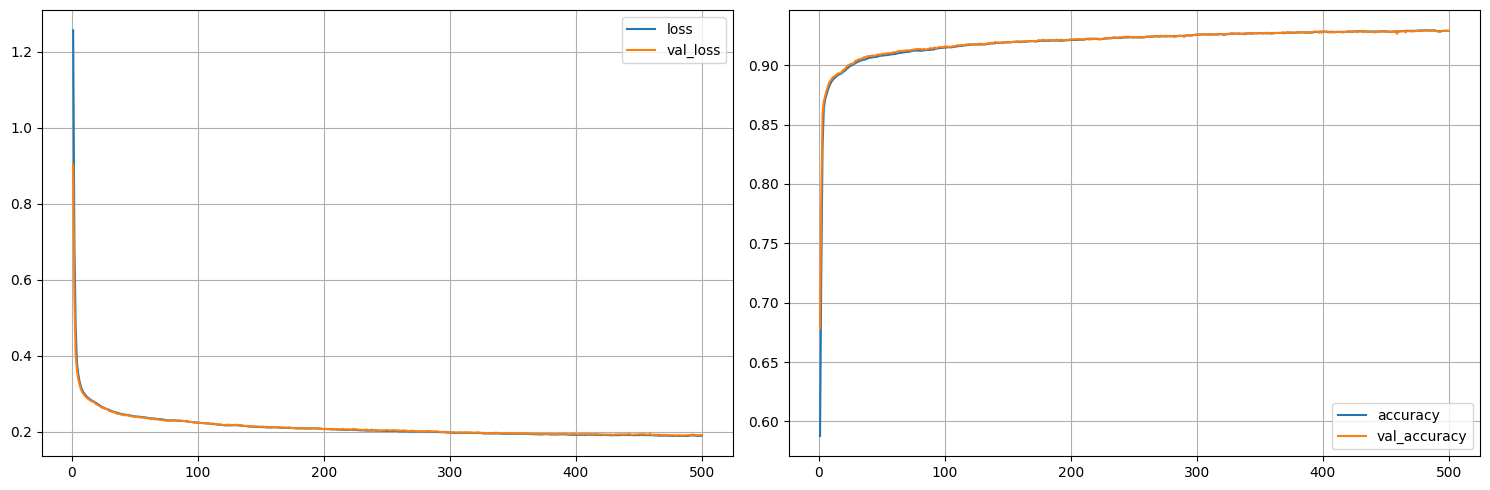

56/56 [==============================] - 2s 30ms/step - loss: 0.1901 - accuracy: 0.9290 - val_loss: 0.1914 - val_accuracy: 0.9289


In [11]:
if(cargarPesos == False):
    # fit network
    model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, validation_data=(X_validation, y_validation),verbose=verbose,callbacks=callbacks_list)
else:
    model.set_weights(weights)

## Evaluar el modelo

In [12]:
# evaluate model
_, accuracy = model.evaluate(X_test, y_test, batch_size=batch_size, verbose=1)

7/7 [==============================] - 0s 13ms/step - loss: 0.1918 - accuracy: 0.9278


In [13]:
y_pred= model.predict(X_test,batch_size=batch_size)

7/7 [==============================] - 0s 12ms/step


In [14]:
y_test_transformado = np.argmax(y_test,axis=1)

In [15]:
y_pred_transformado = np.argmax(y_pred,axis=1)

In [16]:
## Mayor de 0.8 muy bueno

cohen_kappa_score(y_test_transformado, y_pred_transformado)

0.8903646983459325

In [17]:
## Mayor de 0.7 bueno

matthews_corrcoef(y_test_transformado, y_pred_transformado)

0.8967710650407156

In [18]:
log_loss(y_test, y_pred)

0.19184226296178777

In [19]:
roc_auc_score(y_test, y_pred, average="weighted", multi_class="ovr")

0.9696127448872367

In [20]:
clases = ['Chat','Email','FileTransfer','Streaming','VoIP']
print(classification_report(y_test_transformado, y_pred_transformado, target_names = clases))

              precision    recall  f1-score   support

        Chat       0.94      0.81      0.87       131
       Email       0.87      0.81      0.84        16
FileTransfer       0.85      1.00      0.92     26547
   Streaming       0.99      0.77      0.87     20845
        VoIP       1.00      1.00      1.00     21427

    accuracy                           0.93     68966
   macro avg       0.93      0.88      0.90     68966
weighted avg       0.94      0.93      0.93     68966



In [21]:
#label_encoder={0: 'Chat', 1: 'Email', 2: 'FileTransfer', 3: 'Streaming', 4: 'VoIP'}
confusion = confusion_matrix(y_test_transformado, y_pred_transformado, labels = [0,1,2,3,4])
print('Confusion Matrix\n')
print(confusion)

Confusion Matrix

[[  106     0    15     9     1]
 [    0    13     1     1     1]
 [    0     0 26483    58     6]
 [    5     2  4727 16031    80]
 [    2     0    10    59 21356]]


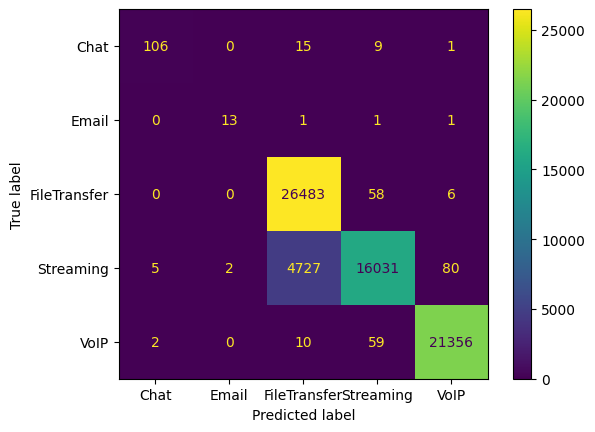

In [22]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion,display_labels=clases)
disp.plot()
plt.show()


## Guardar los pesos del modelo

In [23]:
weights = model.get_weights()

In [24]:
file_pesos_modelo = open('Objetos preprocesados/Pesos_LSTM/'+nombreFicheros+'_pesosLSTM.obj', 'wb') 
pickle.dump(weights, file_pesos_modelo)
file_pesos_modelo.close()